# Grid Methods for Posterior Evaluation

In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import scipy
from scipy import stats, integrate, interpolate, optimize, special
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
try:
    import ipywidgets as widgets
except ImportError:
    widgets = None

# Equivalent working directory: the Jupyter kernel's current directory.
Path.cwd()
plt.rcParams.update({'figure.figsize':(6,4),'figure.dpi':105,'font.size':11,
                     'axes.grid':False,'axes.spines.top':True,'axes.spines.right':True})
rng = np.random.default_rng(2026)  # Original draws are unseeded; this copy is reproducible.
x,y,z,w=sp.symbols('x y z w', real=True)
μ,σ=sp.symbols('μ σ',positive=True)
α,γ,τ=sp.symbols('α γ τ')

# A few reusable equivalents of plotting and numerical operations in the original.
def lineplot(functions, limits, labels=None, ylim=None, title=None, fill=False, n=700):
    if not isinstance(functions,(list,tuple)):functions=[functions]
    grid=np.linspace(*limits,n);fig,ax=plt.subplots()
    for k,fun in enumerate(functions):
        vals=np.broadcast_to(np.asarray(fun(grid),dtype=float),grid.shape)
        ax.plot(grid,vals,label=labels[k] if labels else None)
        if fill and k==0:ax.fill_between(grid,0,vals,alpha=.25)
    ax.set_xlim(*limits)
    if ylim is not None:ax.set_ylim(*ylim)
    if title:ax.set_title(title)
    if labels:ax.legend()
    plt.show();plt.close(fig)
    return fig

def surface(fun,xlim,ylim,n=70,title=None):
    xx,yy=np.meshgrid(np.linspace(*xlim,n),np.linspace(*ylim,n),indexing='ij')
    fig=plt.figure();ax=fig.add_subplot(111,projection='3d')
    ax.plot_surface(xx,yy,np.asarray(fun(xx,yy)),cmap='viridis',linewidth=0,antialiased=True)
    ax.set(xlabel='x',ylabel='y',title=title or '')
    plt.show();plt.close(fig)
    return fig

def manipulate(fun,name,start,stop,value=None,step=None):
    # A static preview is also included so the GitHub view remains useful.
    initial=(start+stop)/2 if value is None else value
    fun(initial)
    if widgets is not None:
        slider=widgets.FloatSlider(value=initial,min=start,max=stop,
            step=step or (stop-start)/100,description=name,continuous_update=False)
        out=widgets.interactive_output(fun,{'value':slider})
        display(widgets.VBox([slider,out]))
    else:
        print('Optional interactive control: install ipywidgets, then rerun this cell.')

class KernelDistribution:
    """Gaussian KDE; bandwidth can be automatic or an absolute width."""
    def __init__(self,data,bandwidth=None,bounds=None):
        self.data=np.asarray(data,float)
        self.bounds=bounds
        if bandwidth is None:
            self.kde=stats.gaussian_kde(self.data,bw_method='silverman')
        else:
            self.kde=stats.gaussian_kde(self.data,bw_method=float(bandwidth)/self.data.std(ddof=1))
        self.width=float(np.sqrt(self.kde.covariance[0,0]))
        if bounds:
            lo,hi=bounds
            self.norm=sum(self.kde.integrate_box_1d(a,b) for a,b in
                [(lo,hi),(2*lo-hi,lo),(hi,2*hi-lo)])
        else:self.norm=1.
    def pdf(self,t):
        t=np.asarray(t,float);flat=t.ravel();values=self.kde(flat)
        if self.bounds:
            lo,hi=self.bounds
            values=(values+self.kde(2*lo-flat)+self.kde(2*hi-flat))/self.norm
            values=np.where((flat>=lo)&(flat<=hi),values,0.)
        return values.reshape(t.shape)
    def cdf(self,t):
        t=np.asarray(t,float)
        if self.bounds:
            lo,hi=self.bounds
            fun=lambda a: integrate.quad(lambda v:float(self.pdf(v)),lo,min(max(a,lo),hi),limit=180)[0]
        else:fun=lambda a:self.kde.integrate_box_1d(-np.inf,a)
        return np.array([fun(a) for a in t.ravel()]).reshape(t.shape)
    def mean(self):
        if self.bounds:
            lo,hi=self.bounds
            return integrate.simpson(np.linspace(lo,hi,1001)*self.pdf(np.linspace(lo,hi,1001)),x=np.linspace(lo,hi,1001))
        return self.data.mean()
    def var(self):
        if self.bounds:
            lo,hi=self.bounds;grid=np.linspace(lo,hi,1001);mean=self.mean()
            return integrate.simpson((grid-mean)**2*self.pdf(grid),x=grid)
        return self.data.var(ddof=0)+self.width**2

def make_interpolator(tab):
    xv=tab[:,0,0];yv=tab[0,:,1]
    interp=interpolate.RegularGridInterpolator((xv,yv),tab[:,:,2],method='linear',bounds_error=False,fill_value=None)
    def fun(a,b):
        aa,bb=np.broadcast_arrays(a,b)
        val=interp(np.column_stack([aa.ravel(),bb.ravel()])).reshape(aa.shape)
        return float(val) if val.ndim==0 else val
    return fun

def grid_table(xv,yv,fun):
    xx,yy=np.meshgrid(xv,yv,indexing='ij')
    return np.stack([xx,yy,fun(xx,yy)],axis=-1)

def contourplot(tab,levels,filled=True,ax=None,style='solid',colors=None):
    own=ax is None
    if own:fig,ax=plt.subplots()
    lev=np.unique(np.sort(np.asarray(levels,float)))
    xx=tab[:,:,0];yy=tab[:,:,1];zz=tab[:,:,2]
    if filled:
        edges=np.r_[-np.inf,lev,np.inf]
        ax.contourf(xx,yy,zz,levels=edges,colors=colors or ['#c36c00','#ffb954','#ffe4bc','white'])
    else:
        ax.contour(xx,yy,zz,levels=lev,colors='black',linestyles=style,linewidths=1.)
    ax.set(xlabel='x',ylabel='y',xlim=(xx.min(),xx.max()),ylim=(yy.min(),yy.max()))
    if own:plt.show();plt.close(fig)
    return ax

def best_grid_maximum(tab,fun,start):
    xmin0,xmax0=tab[:,:,0].min(),tab[:,:,0].max()
    ymin0,ymax0=tab[:,:,1].min(),tab[:,:,1].max()
    local=optimize.minimize(lambda v:-fun(*v),start,method='Powell',
        bounds=[(xmin0,xmax0),(ymin0,ymax0)],options={'xtol':1e-7,'ftol':1e-9})
    flat=tab.reshape(-1,3);row=flat[np.argmax(flat[:,2])]
    # A bilinear interpolant has a global maximum at a grid vertex.
    glob={'maximum':float(row[2]),'x':float(row[0]),'y':float(row[1])}
    return local,glob

def squared_target_min(fun,target,limits):
    # Global scan followed by a local bounded refinement, matching Minimize's aim.
    grid=np.linspace(*limits,12001);vals=(np.asarray(fun(grid))-target)**2
    j=int(np.argmin(vals));a=grid[max(j-1,0)];b=grid[min(j+1,len(grid)-1)]
    res=optimize.minimize_scalar(lambda t:float((fun(t)-target)**2),bounds=(a,b),method='bounded',options={'xatol':1e-12})
    return float(res.x)

def log_grid_thresholds(tab,step=.03,weighted=True):
    vals=tab[:,:,2]
    with np.errstate(divide='ignore'):q=-2*np.log(vals)
    minimum=np.min(q);qrange=minimum+np.arange(0,21+step*.1,step)
    def cut(t):
        a=np.asarray(t);flat=a.ravel()
        result=np.array([vals[q<v].sum()/vals.sum() for v in flat]).reshape(a.shape)
        return float(result) if result.ndim==0 else result
    gg0=interpolate.interp1d(qrange,cut(qrange),kind='quadratic',bounds_error=False,fill_value='extrapolate')
    lev=[squared_target_min(gg0,target,(minimum+lo,minimum+hi)) for target,lo,hi in
         [(.6827,.3,10),(.9545,1,13),(.9973,3,20)]]
    return minimum,qrange,cut,gg0,np.array(lev)

As discussed in the PDF slides, in order to draw confidence-level contours (technically called “highest posterior density interval”) we need to find out for which values of the posterior the integral over the parameters yield a given % of the complete integral.
The threshold values most used are 68% (1σ), 90%, 95% (2σ) and 99.73% (3σ).

## Probability Distributions

The Wolfram Language is very versatile when it comes to statistical distributions
A distribution is a special kind of function. It is nonnegative-definite and its integral over the whole parameter space is unity.

Many functions operate directly on distributions, like PDF, CDF, Probability, Mean, Variance etc.

To study at home: discrete distributions

$\mathrm{PDF}(y)=\frac{1}{\sqrt{2\pi}}\exp[-(y-2)^2/2]$

$\mathrm{CDF}(y)=\frac12[1+\operatorname{erf}((y-2)/\sqrt2)]$

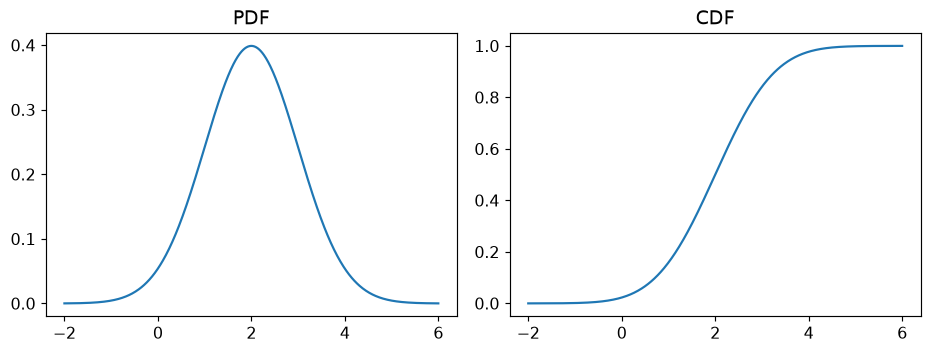

In [2]:
μ,σ=2,1
dist1=stats.norm(loc=μ,scale=σ)
display(Markdown(r'$\mathrm{PDF}(y)=\frac{1}{\sqrt{2\pi}}\exp[-(y-2)^2/2]$'))
display(Markdown(r'$\mathrm{CDF}(y)=\frac12[1+\operatorname{erf}((y-2)/\sqrt2)]$'))
yg=np.linspace(-2,6,700)
fig,axs=plt.subplots(1,2,figsize=(9,3.5))
axs[0].plot(yg,dist1.pdf(yg));axs[1].plot(yg,dist1.cdf(yg))
axs[0].set_title('PDF');axs[1].set_title('CDF')
plt.tight_layout();plt.show();plt.close(fig)

In [3]:
display(dist1.mean())

np.float64(2.0)

sqrt(2)*exp(-(-μ + log(y))**2/(2*σ**2))/(2*sqrt(pi)*y*σ)

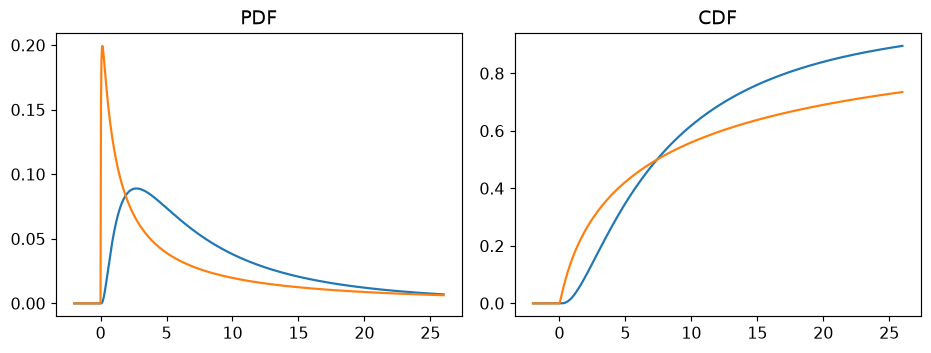

In [4]:
μ,σ=2,1;dist2=stats.lognorm(s=σ,scale=np.exp(μ))
μ,σ=2,2;dist3=stats.lognorm(s=σ,scale=np.exp(μ))
μ,σ=sp.symbols('μ σ',positive=True)
display(sp.exp(-(sp.log(y)-μ)**2/(2*σ**2))/(sp.sqrt(2*sp.pi)*σ*y))
yg=np.linspace(-2,26,800)
fig,axs=plt.subplots(1,2,figsize=(9,3.5))
for di in [dist2,dist3]:axs[0].plot(yg,di.pdf(yg));axs[1].plot(yg,di.cdf(yg))
axs[0].set_title('PDF');axs[1].set_title('CDF')
plt.tight_layout();plt.show();plt.close(fig)

In [5]:
display((dist2.mean(),dist2.var()))
display((μ,σ**2))
display((sp.exp(μ+σ**2/2),(sp.exp(σ**2)-1)*sp.exp(2*μ+σ**2)))
display((μ,μ))
display(sp.sqrt(μ))

(np.float64(12.182493960703473), np.float64(255.0156343901585))

(μ, σ**2)

(exp(μ + σ**2/2), (exp(σ**2) - 1)*exp(2*μ + σ**2))

(μ, μ)

sqrt(μ)

E.g.: The Maxwell-Boltzmann velocity distribution

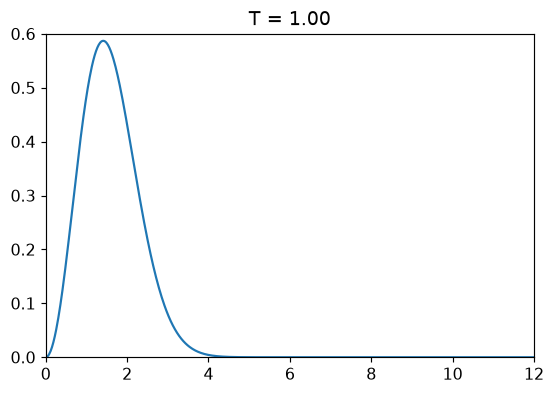

In [16]:
sqrtT=sp.symbols('sqrtT',positive=True)
maxwell_pdf=sp.sqrt(2/sp.pi)*x**2*sp.exp(-x**2/(2*sqrtT**2))/sqrtT**3
display(maxwell_pdf)
display((2*sqrtT*sp.sqrt(2/sp.pi),sp.sqrt(2)*sqrtT))
def plot_maxwell(value):
    lineplot(lambda t:stats.maxwell.pdf(t,scale=np.sqrt(value)),(0,12),ylim=(0,.6),title=f'T = {value:.2f}')
manipulate(plot_maxwell,'T',1,10,value=1)

Two important operators for random variables:
x ∼ dist   ->   the random variable “x” is distributed according to the distribution dist   (hotkey dist)
expr | cond   ->   the expression expr is conditioned to the hypothesis cond   (hotkey cond)

In [7]:
display(dist1.cdf(5)-dist1.cdf(-1))
root=optimize.brentq(lambda a:a*np.tanh(a)-1,0,4)
prob_tanh=dist1.cdf(root)-dist1.cdf(-root)
display(prob_tanh)
display(float(prob_tanh))

np.float64(0.9973002039367398)

np.float64(0.21107441086611764)

0.21107441086611764

### Transformed Distributions

We often need to carry out change of variables in probability
TransformedDistribution is an inbuilt function for that
If the resulting distribution is not tabulated, further computation will be slow

In [17]:
display(Markdown(r'$3X+1\sim\mathcal N(3\mu+1,9\sigma^2)$'))
display(Markdown(r'$\exp(X)\sim\operatorname{LogNormal}(\mu,\sigma)$'))

$3X+1\sim\mathcal N(3\mu+1,9\sigma^2)$

$\exp(X)\sim\operatorname{LogNormal}(\mu,\sigma)$

$X^2\sim\chi^2_1$

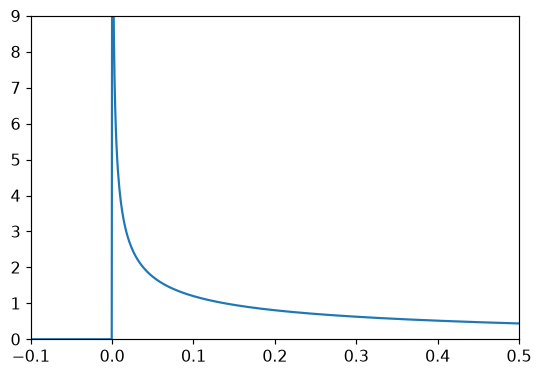

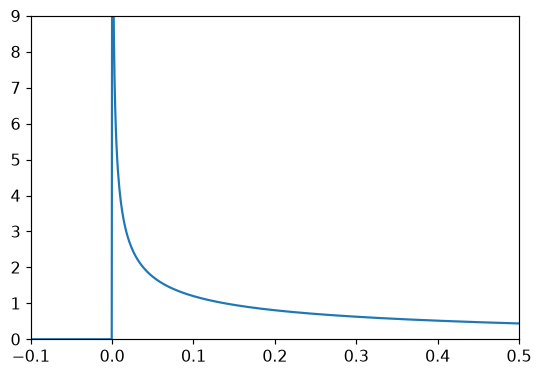

In [19]:
x,y,z=sp.symbols('x y z',real=True)
dist4=stats.chi2(df=1)
display(Markdown(r'$X^2\sim\chi^2_1$'))
lineplot(dist4.pdf,(-.1,.5),ylim=(0,9))

$X^2+Y^2+Z^2\sim\chi^2_3$

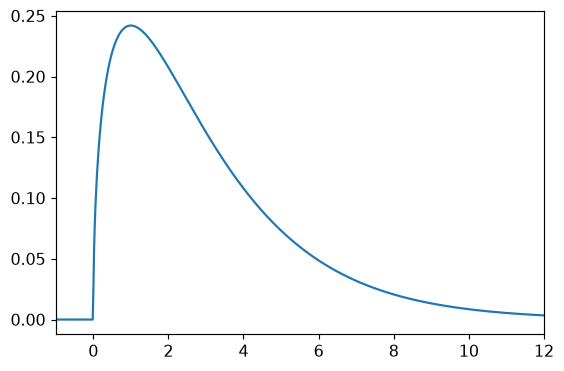

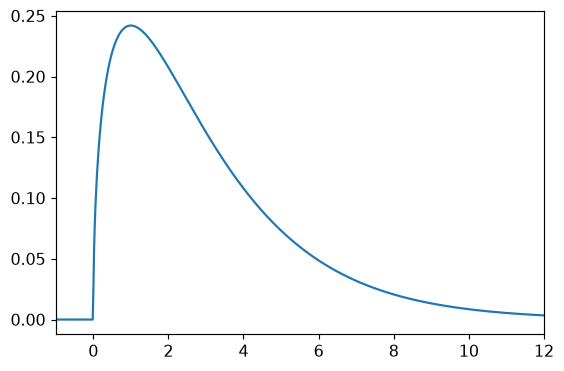

In [20]:
dist5=stats.chi2(df=3)
display(Markdown(r'$X^2+Y^2+Z^2\sim\chi^2_3$'))
lineplot(dist5.pdf,(-1,12))

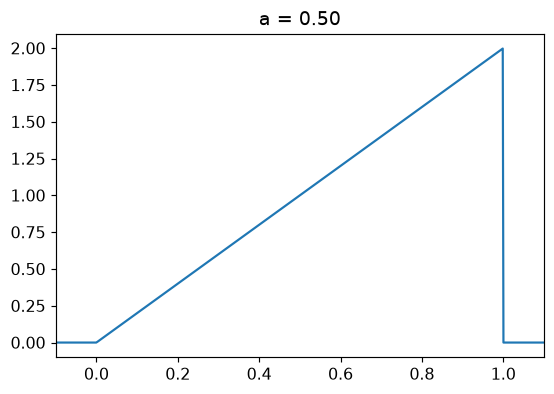

In [26]:
a=sp.symbols('a',positive=True)
display(Markdown(r'$X\sim U(0,1),\ Y=X^a:\quad p_Y(y)=y^{1/a-1}/a,\quad0<y<1.$'))
def power_pdf(t,aa):
    t=np.asarray(t,float);out=np.zeros(t.shape);mask=(t>0)&(t<1)
    out[mask]=t[mask]**(1/aa-1)/aa
    return out
def plot_power(value):lineplot(lambda t:power_pdf(t,value),(-.1,1.1),title=f'a = {value:.2f}')
manipulate(plot_power,'aa',.2,2,value=0.5)

In [24]:
display(sp.Piecewise((x**(1/a-1)/a,sp.And(x>0,x<1)),(0,True)))

Piecewise((x**(-1 + 1/a)/a, (x > 0) & (x < 1)), (0, True))

Some distributions do not have well-defined mean and/or variance

$X/Y\sim\operatorname{Cauchy}(0,\sigma_1/\sigma_2)$

nan

0

nan

σ1*σ2/(pi*(x**2*σ2**2 + σ1**2))

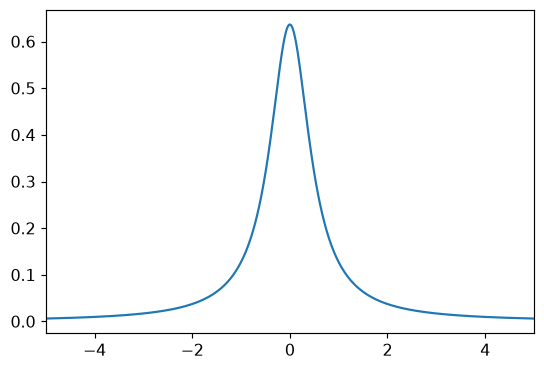

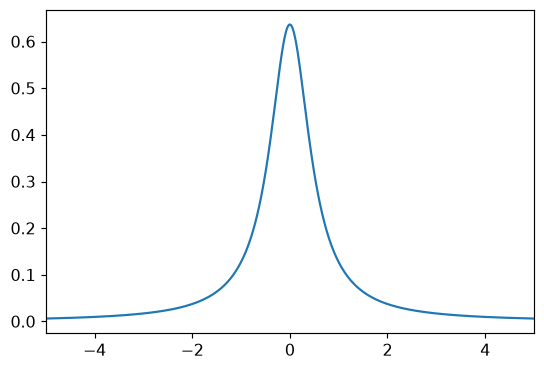

In [27]:
σ1,σ2=sp.symbols('σ1 σ2',positive=True)
display(Markdown(r'$X/Y\sim\operatorname{Cauchy}(0,\sigma_1/\sigma_2)$'))
display(sp.nan)  # Mean is undefined.
display(0)       # Median.
display(sp.nan)  # Variance is undefined.
display(σ1*σ2/(sp.pi*(σ1**2+σ2**2*x**2)))
lineplot(lambda t:stats.cauchy.pdf(t,scale=1/2),(-5,5))

Mathematica has trouble finding TransformedDistribution expressions in some cases. This can be critical (nothing works) or at least very time-consuming

In [28]:
# X and Y are independent, X~N(0,σ1²), Y~N(1,σ2²).
display(Markdown(r'$Z=XY,\quad X\sim\mathcal N(0,\sigma_1^2),\quad Y\sim\mathcal N(1,\sigma_2^2)$'))
display(0)
display(0)  # Symmetry around zero.
display(σ1**2*(1+σ2**2))
# The plot is commented out in the original.

$Z=XY,\quad X\sim\mathcal N(0,\sigma_1^2),\quad Y\sim\mathcal N(1,\sigma_2^2)$

0

0

σ1**2*(σ2**2 + 1)

An alternative is to compute a transformed distribution numerically (see below)

### Creating your own distribution from data

(np.float64(-0.00012398825150253696), np.float64(1.0022486743173757))

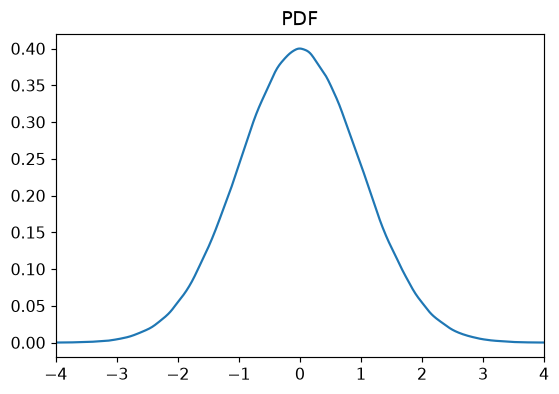

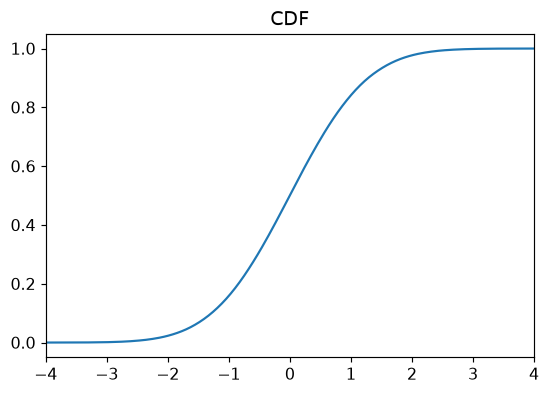

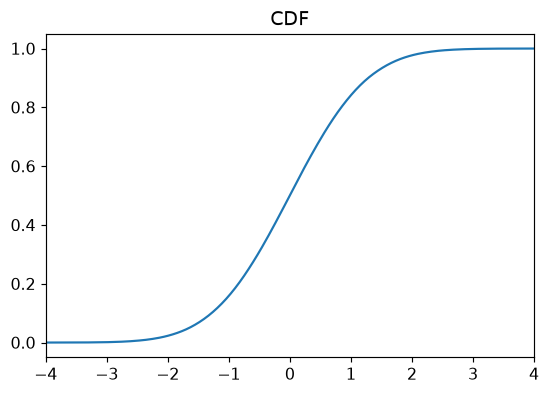

In [30]:
data=rng.normal(0,1,10**6)
scriptD=KernelDistribution(data)
display((scriptD.mean(),np.sqrt(scriptD.var())))
lineplot(scriptD.pdf,(-4,4),title='PDF')
lineplot(scriptD.cdf,(-4,4),title='CDF',n=220)

Computing a transformed distribution numerically with large number of samples (here we will use (10)^(5) which is in general fast and accurate)

np.float64(-0.0008288461012533844)

np.float64(0.0015372796269875319)

np.float64(32.05747505291887)

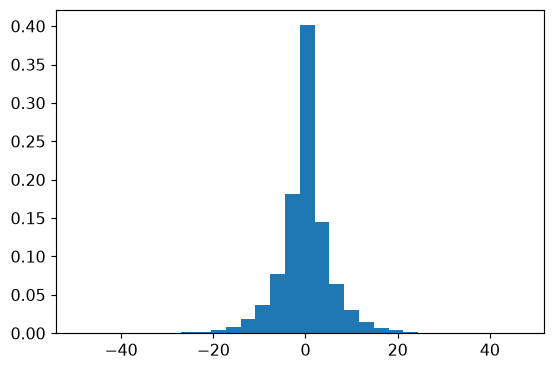

In [31]:
xx=rng.normal(0,2,10**5)
yy=rng.normal(2,2,10**5)
zz=xx*yy
display(zz.mean());display(np.median(zz));display(zz.var(ddof=1))
fig,ax=plt.subplots();ax.hist(zz,bins=30,weights=np.ones(len(zz))/len(zz));plt.show();plt.close(fig)

(np.float64(-49.36209304052702), np.float64(46.928131024953814))

np.float64(-0.0008288461012533844)

np.float64(32.41682496902469)

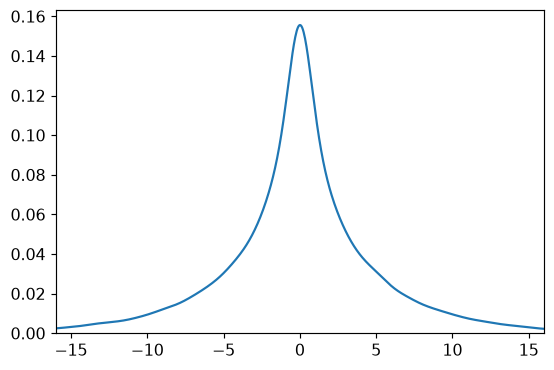

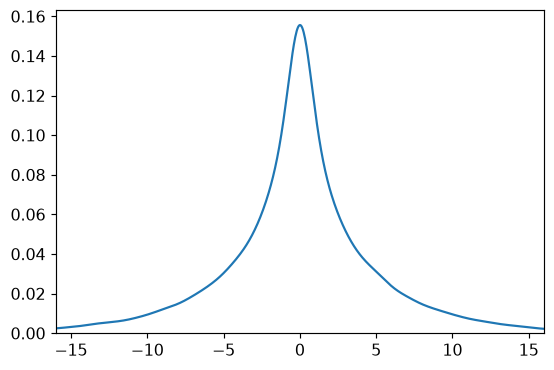

In [32]:
display((zz.min(),zz.max()))
dist9a=KernelDistribution(zz)
display(dist9a.mean());display(dist9a.var())
lineplot(dist9a.pdf,(-16,16),ylim=(0,None))

np.float64(14.003936120833329)

np.float64(9.685945169672916)

np.float64(195.47526716806104)

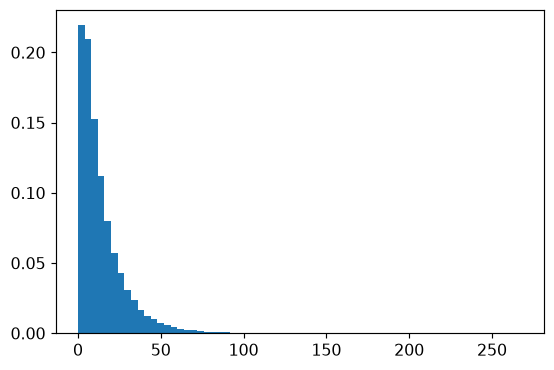

In [33]:
xx=rng.normal(0,1,10**5);yy=rng.normal(0,2,10**5);ww=rng.normal(0,3,10**5)
zz=xx**2+yy**2+ww**2
display(zz.mean());display(np.median(zz));display(zz.var(ddof=1))
hist_edges=np.arange(0,np.ceil(zz.max()/4)*4+4,4)
hist=(zz.copy(),hist_edges.copy())
fig,ax=plt.subplots();ax.hist(hist[0],bins=hist[1],weights=np.ones(len(zz))/len(zz));plt.show();plt.close(fig)

Smooth kernel distributions may extrapolate into forbidden regions. Below, suppose we know that x  >=  0. The simple smoothing will spill over to negative x regions.

(np.float64(0.006891161884255538), np.float64(264.8301845022269))

np.float64(14.003936120833329)

np.float64(197.6664572334561)

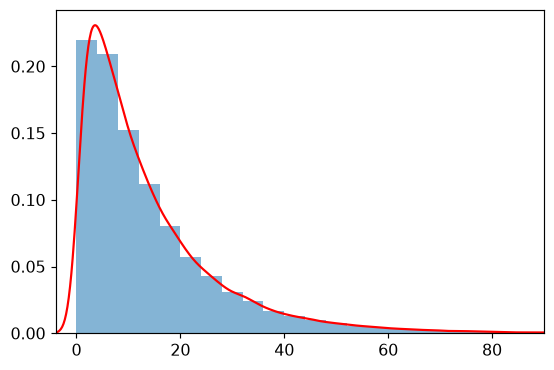

In [34]:
display((zz.min(),zz.max()))
dist9a=KernelDistribution(zz)
display(dist9a.mean());display(dist9a.var())
def show_hist_smooth(distribution,limits=(-4,90)):
    fig,ax=plt.subplots();ax.hist(hist[0],bins=hist[1],weights=np.ones(len(hist[0]))/len(hist[0]),alpha=.55)
    gg=np.linspace(*limits,750);ax.plot(gg,4*distribution.pdf(gg),color='red');ax.set(xlim=limits,ylim=(0,None))
    plt.show();plt.close(fig);return fig
psmooth=show_hist_smooth(dist9a)

The option below “bounds” the distribution to the desired x  >=  0 region

(np.float64(0.006891161884255538), np.float64(264.8301845022269))

np.float64(14.002443158688559)

np.float64(187.93614738332232)

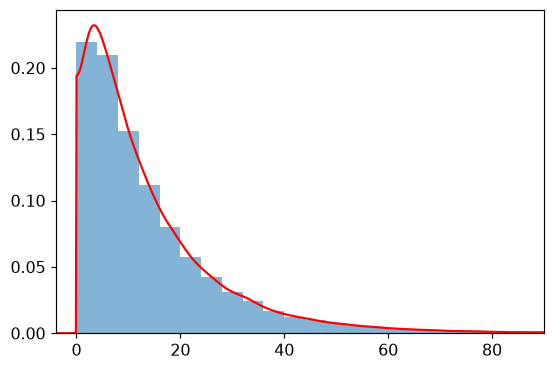

In [35]:
display((zz.min(),zz.max()))
# Reflected Gaussian KDE on [0,100], normalized on that same support.
# Automatic bandwidth selection / boundary correction may differ across software.
dist9b=KernelDistribution(zz,bounds=(0,100))
display(dist9b.mean());display(dist9b.var())
psmooth2=show_hist_smooth(dist9b)

**Smaller** bandwidths also prevents long tails spilling over, but may result in a noisy distribution.

(np.float64(0.006891161884255538), np.float64(264.8301845022269))

np.float64(14.003936120833329)

np.float64(195.47581241538933)

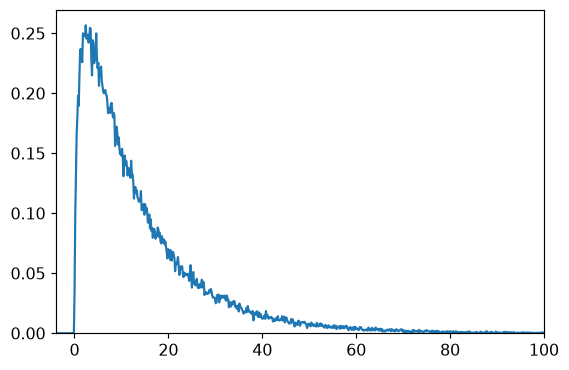

In [36]:
display((zz.min(),zz.max()))
dist9a=KernelDistribution(zz,bandwidth=.05)
display(dist9a.mean());display(dist9a.var())
psmooth3=lineplot(lambda t:4*dist9a.pdf(t),(-4,100),ylim=(0,None))

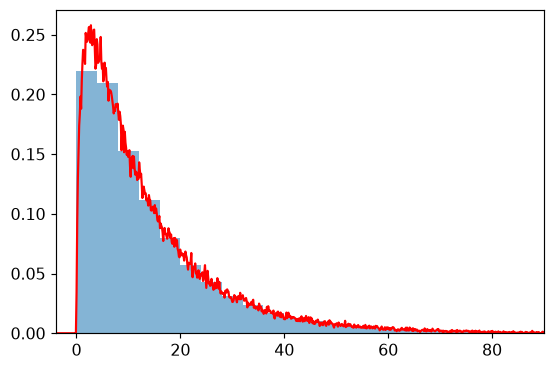

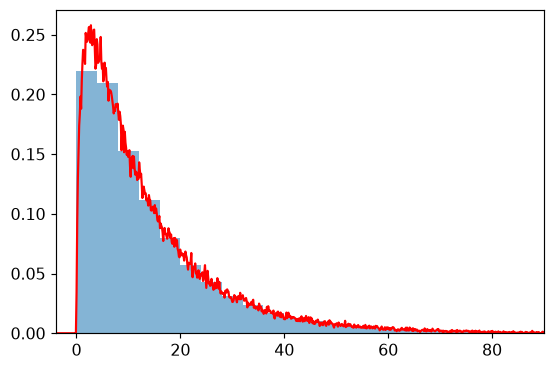

In [37]:
show_hist_smooth(dist9a)

### Central Limit Theorem for Cauchy distribution?

sqrt(2)*exp(-Abs(k))/(2*sqrt(pi))

2/(pi*(x**2 + 4))

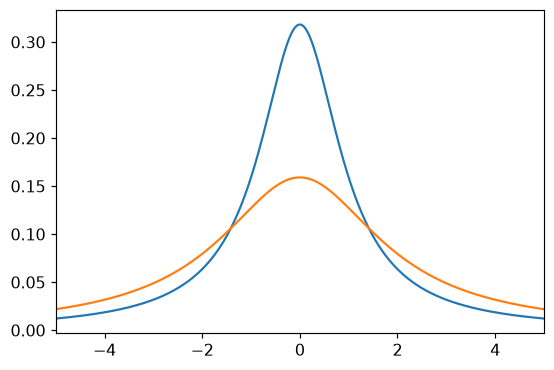

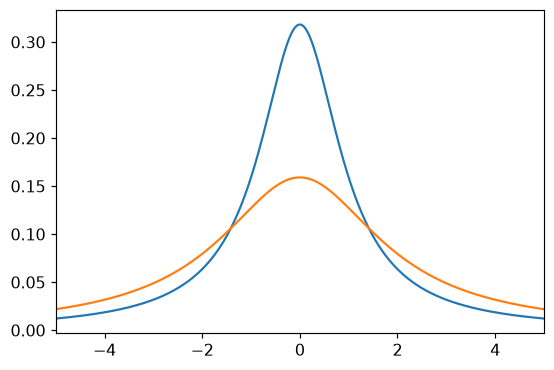

In [38]:
# Mathematica default: symmetric Fourier normalization, exp(+ikx).
f1=lambda t:stats.cauchy.pdf(t,loc=0,scale=1)
f2_cauchy=lambda t:stats.cauchy.pdf(t,loc=0,scale=1)
k=sp.symbols('k',real=True)
f1k=sp.exp(-sp.Abs(k))/sp.sqrt(2*sp.pi)
f2k=f1k
f12_cauchy=lambda t:stats.cauchy.pdf(t,scale=2)
display(f1k);display(2/(sp.pi*(x**2+4)))
lineplot([f1,f12_cauchy],(-5,5))

In [39]:
f1=lambda t:stats.cauchy.pdf(t,scale=1)
f2_normal=lambda t:stats.norm.pdf(t)
f1k=sp.exp(-sp.Abs(k))/sp.sqrt(2*sp.pi)
f2k=sp.exp(-k**2/2)/sp.sqrt(2*sp.pi)
# Convolution of a Cauchy(0,1) and Normal(0,1): Voigt profile.
f12=lambda t:special.voigt_profile(t,1.,1.)
display(f1k);display(f2k)

sqrt(2)*exp(-Abs(k))/(2*sqrt(pi))

sqrt(2)*exp(-k**2/2)/(2*sqrt(pi))

In [40]:
# One Cauchy plus three independent standard normals.
f1234=lambda t:special.voigt_profile(t,np.sqrt(3),1.)

In [41]:
display(integrate.quad(lambda t:float(f1234(t)),-np.inf,np.inf,epsabs=1e-9)[0])

1.0000000000000002

In [42]:
# The second moment diverges because the Cauchy tail persists.
display(sp.oo)

oo

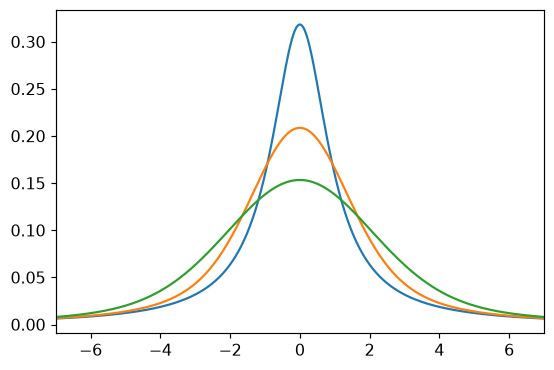

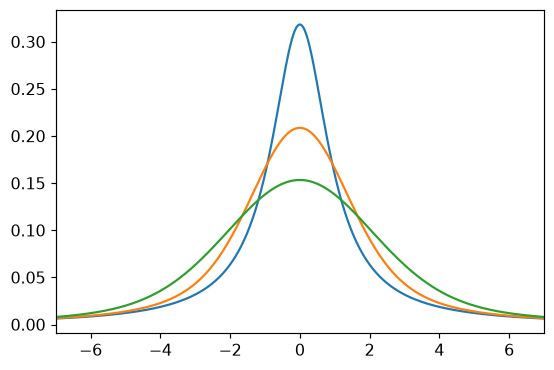

In [43]:
# σ1234 is left undefined in the original; its Gaussian comparison cannot be evaluated.
# Set a positive numeric value here to add an arbitrary Gaussian reference.
σ1234=None
curves=[f1,f12,f1234]
if σ1234 is not None:curves.append(lambda t:stats.norm.pdf(t,scale=σ1234))
lineplot(curves,(-7,7))

## Finding  Contours

### 1D Case

**Suppose** our posterior is a trivial Gaussian function of zero mean and σ = 1/2   ->   (E)^(-(1)/(2)(((x)/(2)))^(2)) 
The function below computes the integral in the parameter x above a given threshold z of the posterior. We want to find z for which this integral is, say, 68% of the complete integral (i.e. the one for z = 0).

*Source transcription note: the prose says σ = 1/2, while the actual formula and code use σ = 2. The executable formula is preserved exactly.*

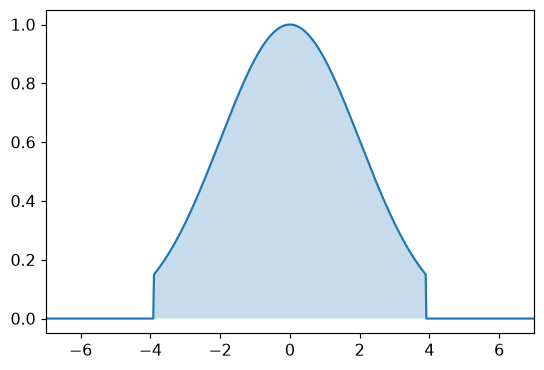

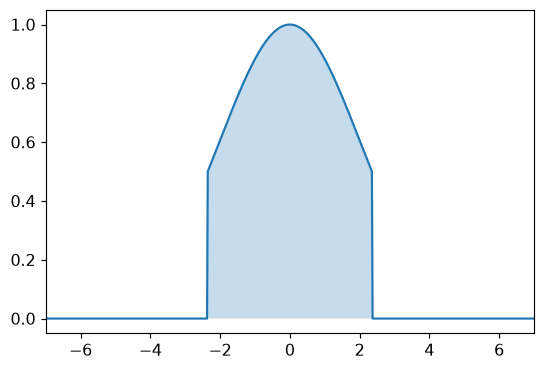

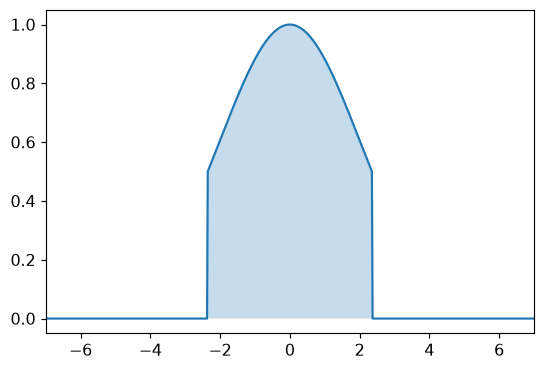

In [45]:
# Formula kept exactly: exp[-(1/2)(x/2)^2], which has width 2.
def pdf(x,z):
    val=np.exp(-.5*(np.asarray(x)/2)**2)
    return np.where(val>z,val,0.)
lineplot(lambda t:pdf(t,.15),(-7,7),fill=True)
lineplot(lambda t:pdf(t,.5),(-7,7),fill=True)

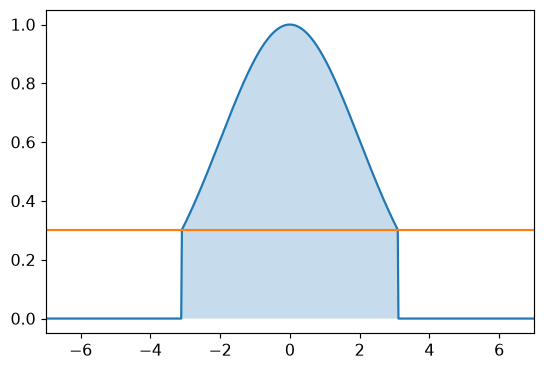

In [46]:
def plot_cut(value):lineplot([lambda t:pdf(t,value),lambda t:np.full_like(t,value)],(-7,7),fill=True)
manipulate(plot_cut,'cut',0,1,value=.3)

norm is the normalization factor (our pdf was not normalized!)

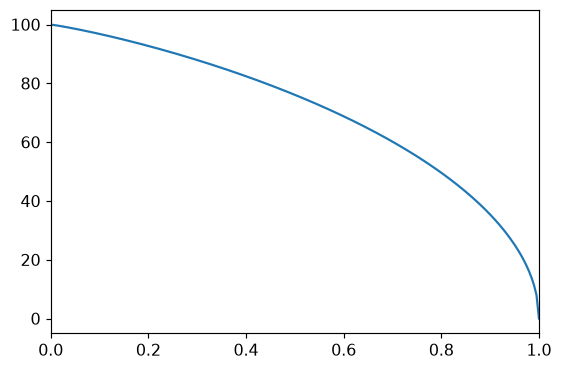

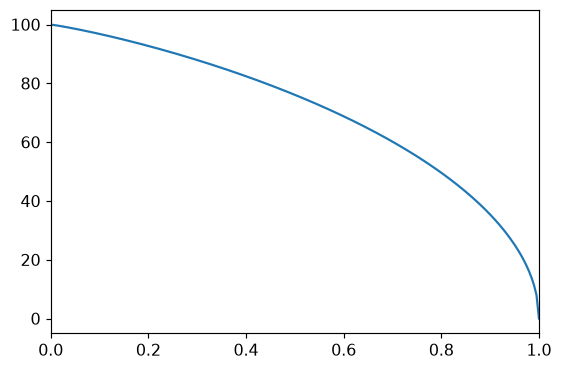

In [48]:
norm=1/integrate.quad(lambda t:np.exp(-.5*(t/2)**2),-20,20)[0]
def fintegrated(z):
    # Integrate the same thresholded Gaussian, splitting at its discontinuities.
    if z<=0:return 1.
    if z>=1:return 0.
    edge=min(20.,2*np.sqrt(-2*np.log(z)))
    return norm*integrate.quad(lambda t:np.exp(-.5*(t/2)**2),-edge,edge)[0]
lineplot(lambda t:100*np.array([fintegrated(a) for a in t]),(0,1),n=200)

Even in 1D using Plot can be slow and inefficient because each plot point takes a long time to compute and is not being stored anywhere

array([[0.        , 1.        ],
       [0.05      , 0.98562474],
       [0.1       , 0.96812431],
       [0.15      , 0.94857078],
       [0.2       , 0.92720639],
       [0.25      , 0.90410903],
       [0.3       , 0.8792793 ],
       [0.35      , 0.85266659],
       [0.4       , 0.82417706],
       [0.45      , 0.79367331],
       [0.5       , 0.76096811],
       [0.55      , 0.72581198],
       [0.6       , 0.68787235],
       [0.65      , 0.64669912],
       [0.7       , 0.60166603],
       [0.75      , 0.55186481],
       [0.8       , 0.49589656],
       [0.85      , 0.43140431],
       [0.9       , 0.35379715],
       [0.95      , 0.25125257],
       [1.        , 0.        ]])

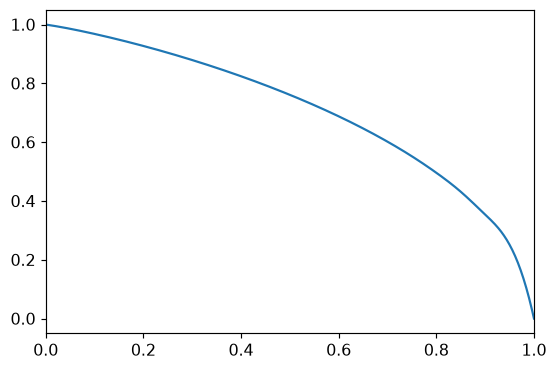

0.6061420299515453

In [49]:
zvec=np.linspace(0,1,21)
fintegratedvec=np.array([[zi,fintegrated(zi)] for zi in zvec])
display(fintegratedvec)
fintegratedfun=interpolate.CubicSpline(fintegratedvec[:,0],fintegratedvec[:,1])
lineplot(fintegratedfun,(0,1))
z1σ=optimize.brentq(lambda t:float(fintegratedfun(t))-.683,0,1)
display(z1σ)

z1σ is the value of the pdf corresponding to the 1σ threshold

In [50]:
x1σlower=optimize.brentq(lambda t:float(pdf(t,0))-z1σ,-20,0)
x1σupper=optimize.brentq(lambda t:float(pdf(t,0))-z1σ,0,20)
display({'x':x1σlower});display({'x':x1σupper})

{'x': -2.0012814844824094}

{'x': 2.0012814844824094}

### Grid Posterior Analysis Simple function

Let' s assume for simplicity that we know the likelihood analytically. This in practice is not the case, and we have in general a complicated function of the data. But this has a didactical advantage : everything is faster AND it is easy to check if we did things right

In [51]:
# NumPy vectorization replaces the original four Mathematica subkernels.
print('Grid evaluation uses vectorized NumPy operations.')

Grid evaluation uses vectorized NumPy operations.


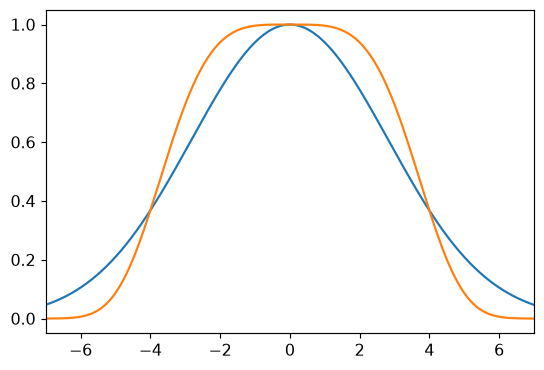

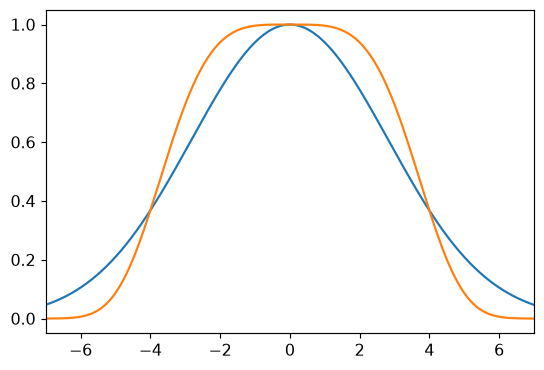

In [52]:
μz,σz=0,2
lineplot([lambda t:np.exp(-((t-μz)/(2*σz))**2),lambda t:np.exp(-((t-μz)/(2*σz))**4)],(-7,7))

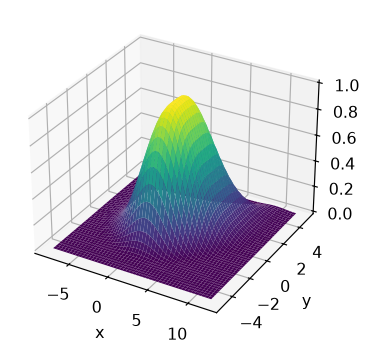

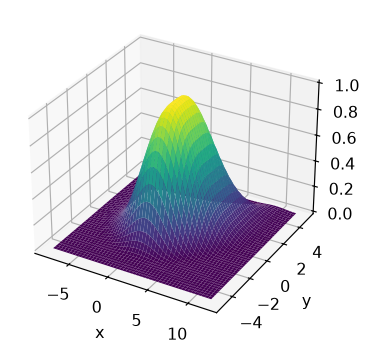

In [53]:
μx,σx,μy,σy=2,2,0,1.2
def likelihood(x,y):
    return np.exp(-((np.asarray(x)-μx)/(2*σx))**2)*np.exp(-((np.asarray(y)-.03*np.asarray(x)**2-μy)/(2*σy))**4)
surface(likelihood,(-8,12),(-5,5),n=50)

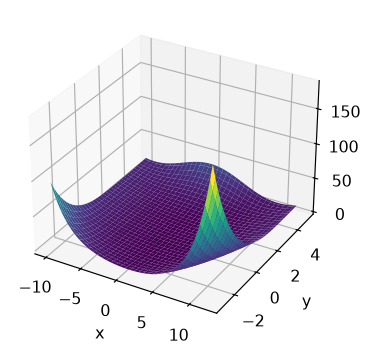

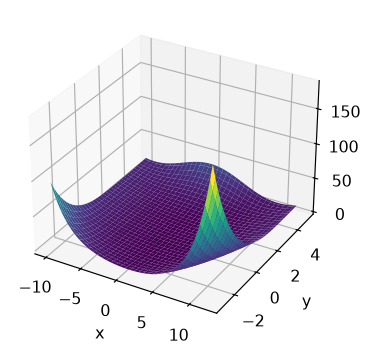

In [54]:
surface(lambda a,b:-2*np.log(likelihood(a,b)),(-10,12),(-3,5))

In [55]:
def prior(x,y):return 1.
def posterior(i,j):return prior(i,j)*likelihood(i,j)
xdimension,ydimension=2*np.array([20,20])
xmin,xmax=-10,14;ymin,ymax=-6,6
Δx=(xmax-xmin)/(xdimension-1);Δy=(ymax-ymin)/(ydimension-1)
xvec=np.linspace(xmin,xmax,xdimension);yvec=np.linspace(ymin,ymax,ydimension)
display(yvec);display(len(yvec))

array([-6.        , -5.69230769, -5.38461538, -5.07692308, -4.76923077,
       -4.46153846, -4.15384615, -3.84615385, -3.53846154, -3.23076923,
       -2.92307692, -2.61538462, -2.30769231, -2.        , -1.69230769,
       -1.38461538, -1.07692308, -0.76923077, -0.46153846, -0.15384615,
        0.15384615,  0.46153846,  0.76923077,  1.07692308,  1.38461538,
        1.69230769,  2.        ,  2.30769231,  2.61538462,  2.92307692,
        3.23076923,  3.53846154,  3.84615385,  4.15384615,  4.46153846,
        4.76923077,  5.07692308,  5.38461538,  5.69230769,  6.        ])

40

The best-fit values (maximum posterior) can be inferred directly from the grid, or from the more smooth interpolated functions

In [57]:
t0=perf_counter();posteriortab=grid_table(xvec,yvec,posterior)
display((perf_counter()-t0,None))
display(posteriortab.shape);display(posteriortab.reshape(-1,3).shape)

(0.0015763600094942376, None)

(40, 40, 3)

(1600, 3)

The best-fit values (maximum posterior) can be inferred directly from the grid, or from the more smooth interpolated functions

In [58]:
sorted_grid=posteriortab.reshape(-1,3)[np.argsort(-posteriortab.reshape(-1,3)[:,2])]
display(sorted_grid)

array([[ 2.30769231e+000,  1.53846154e-001,  9.94100312e-001],
       [ 1.69230769e+000,  1.53846154e-001,  9.94099674e-001],
       [ 1.69230769e+000, -1.53846154e-001,  9.94001299e-001],
       ...,
       [ 1.33846154e+001, -6.00000000e+000,  2.36326929e-223],
       [ 1.40000000e+001, -5.69230769e+000,  2.15764663e-239],
       [ 1.40000000e+001, -6.00000000e+000,  2.25363258e-265]],
      shape=(1600, 3))

In [59]:
posteriorfun=make_interpolator(posteriortab)
local,aux=best_grid_maximum(posteriortab,posteriorfun,[4,2])
display({'local maximum':-local.fun,'parameters':local.x});display(aux)
zmax=aux['maximum'];display(zmax)

{'local maximum': 0.9941003121060822,
 'parameters': array([2.30769231, 0.15384616])}

{'maximum': 0.9941003121114372,
 'x': 2.3076923076923084,
 'y': 0.1538461538461542}

0.9941003121114372

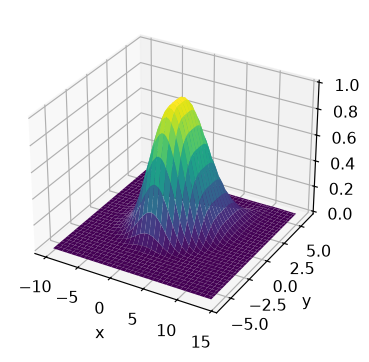

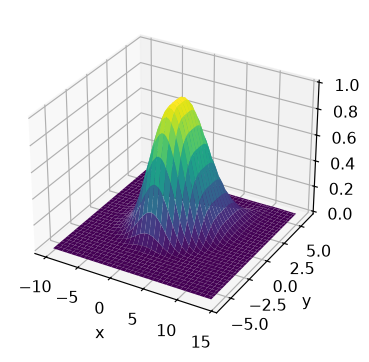

In [60]:
surface(posteriorfun,(xmin,xmax),(ymin,ymax),n=70)

Let's compute the thresholds (contour levels) corresponding to 1, 2 and 3σ

In [61]:
postInt=Δx*Δy*posteriortab[:,:,2].sum()
minchisq,chisqrange,postcut,gg,contourstab=log_grid_thresholds(posteriortab,step=.03)
dim1,dim2=posteriortab.shape[:2];display((dim1,dim2))
c1sig,c2sig,c3sig=contourstab
display(contourstab);display(gg(contourstab))

(40, 40)

array([ 1.61496395,  5.22279289, 10.25638086])

array([0.6827, 0.9545, 0.9973])

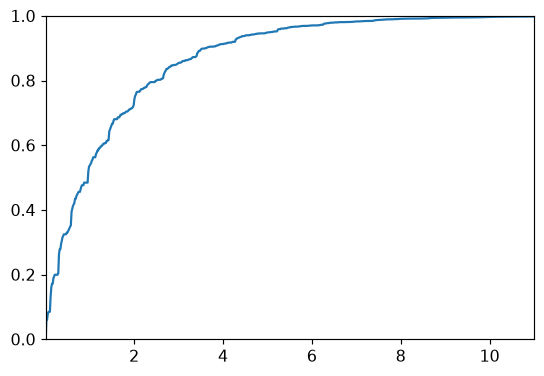

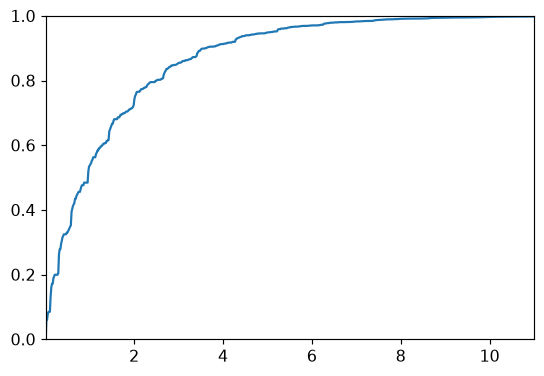

In [62]:
lineplot(postcut,(minchisq,11),ylim=(0,1),n=700)

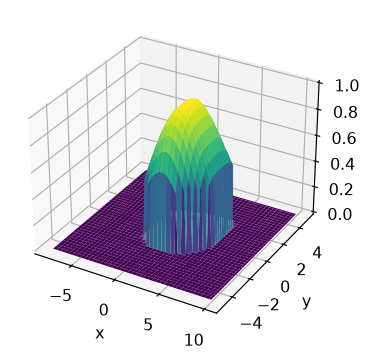

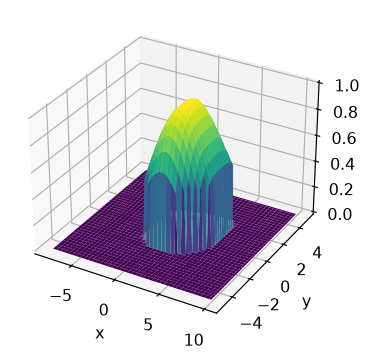

In [63]:
def fz(x,y,z):return np.maximum(posteriorfun(x,y),z)
def f2z(x,y,z):
    val=posteriorfun(x,y)
    return np.where(val>z,val,0.)
surface(lambda a,b:f2z(a,b,np.exp(-.5*c1sig)),(-8,10),(-5,5),n=80)

(1600, 3)

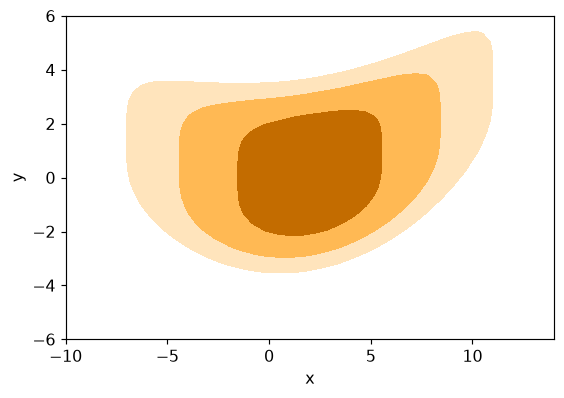

In [64]:
chisqtab=posteriortab.copy();chisqtab[:,:,2]=-2*np.log(posteriortab[:,:,2])
chisqtabflat=chisqtab.reshape(-1,3);display(chisqtabflat.shape)
plot123σ=contourplot(chisqtab,contourstab)

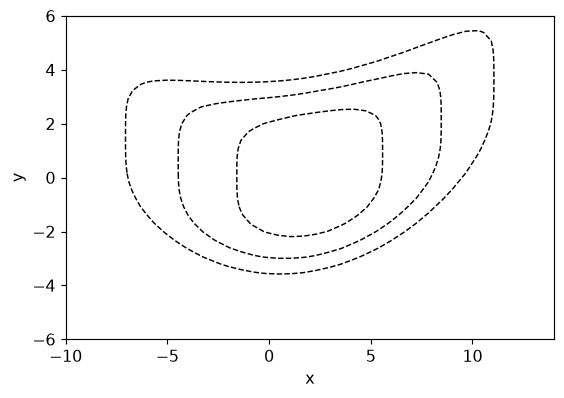

In [65]:
plot123σalt=contourplot(chisqtab,contourstab,filled=False,style='dashed')
# Retain the simple case for the final comparison, just as the original stores its plot.
simple_chisqtab=chisqtab.copy();simple_contours=contourstab.copy()
simple_grid=posteriortab.copy()

### Grid Posterior Analysis Multi-modal

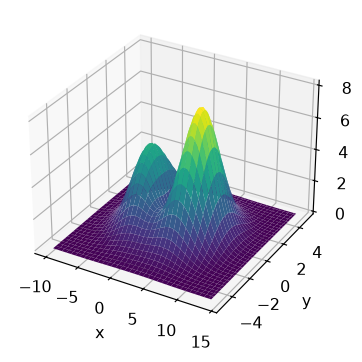

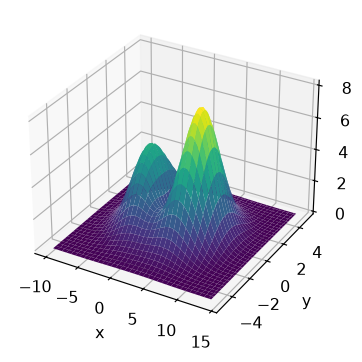

In [66]:
μx,σx,μy,σy=2,2,0,1
def likelihood(x,y):
    return np.exp(-((np.asarray(x)-μx)/(2*σx))**2)*np.exp(-((np.asarray(y)-μy)/(2*σy))**2)*((np.asarray(x)-1.5)**2+(np.asarray(y)**2+1.5))
surface(likelihood,(-10,14),(-5,5))

In [67]:
display(integrate.dblquad(lambda b,a:float(likelihood(a,b)),-10,10,lambda a:-10,lambda a:10,epsabs=1e-6)[0])

289.90249751084366

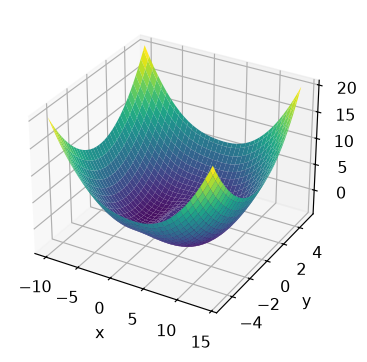

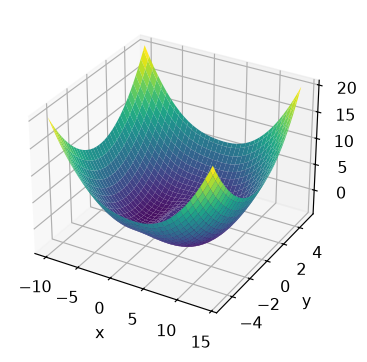

In [68]:
surface(lambda a,b:-2*np.log(likelihood(a,b)),(-10,14),(-5,5))

In [69]:
def prior(x,y):return 1.
def posterior(i,j):return prior(i,j)*likelihood(i,j)
xdimension,ydimension=101,101
xvec=np.linspace(-10,14,xdimension);yvec=np.linspace(-10,10,ydimension)

In [70]:
t0=perf_counter();posteriortab=grid_table(xvec,yvec,posterior)
display((perf_counter()-t0,None));display(posteriortab.shape)

(0.002014989993767813, None)

(101, 101, 3)

In [71]:
t0=perf_counter()
flat=posteriortab.reshape(-1,3)
posteriortabforinterp=[(row[:2].copy(),float(row[2])) for row in flat]
display((perf_counter()-t0,None));display((len(posteriortabforinterp),2))
posteriorfun=make_interpolator(posteriortab)
display(posteriorfun(0,0))

(0.015248046998749487, None)

(10201, 2)

2.9215936211707665

In [72]:
flatposteriortab=np.concatenate([np.r_[p,v] for p,v in posteriortabforinterp])
display(flatposteriortab.shape)

(30603,)

In [73]:
display(posteriortab[:,:,2].max());display(posteriortab[:,:,2].min())

np.float64(8.145351192542053)

np.float64(4.006260958729456e-13)

In [74]:
local,aux=best_grid_maximum(posteriortab,posteriorfun,[5,2])
display({'local maximum':-local.fun,'parameters':local.x});display(aux)
zmax=aux['maximum'];display(zmax)

{'local maximum': 8.145351189800097,
 'parameters': array([5.59999999e+00, 6.21724894e-15])}

{'maximum': 8.145351192542053, 'x': 5.6, 'y': 0.0}

8.145351192542053

In [75]:
def fz(x,y,z):return np.maximum(posteriorfun(x,y),z)
def f2z(x,y,z):
    val=posteriorfun(x,y)
    return np.where(val>z,val,0.)
# Numerical integration of the same bilinear interpolant over the original rectangle.
# Trapezoidal quadrature is vectorized to replace repeated slow adaptive 2D calls.
qx=np.linspace(-10,12,1101);qy=np.linspace(-10,10,1001)
qxx,qyy=np.meshgrid(qx,qy,indexing='ij');qvalues=posteriorfun(qxx,qyy)
qxweights=np.ones(len(qx));qyweights=np.ones(len(qy));qxweights[[0,-1]]=.5;qyweights[[0,-1]]=.5
qweights=np.outer(qxweights,qyweights)*(qx[1]-qx[0])*(qy[1]-qy[0])
norm=np.sum(qweights*qvalues)
qorder=np.argsort(qvalues.ravel());qsorted=qvalues.ravel()[qorder]
qmasses=np.cumsum((qweights*qvalues).ravel()[qorder])
def f3z(z):
    vals=np.asarray(z);indices=np.searchsorted(qsorted,vals,side='right')
    excluded=np.where(indices>0,qmasses[np.maximum(indices-1,0)],0.)
    return (norm-excluded)/norm

In [76]:
zvec=np.linspace(0,.7*zmax,16)
display(zvec)
t0=perf_counter();f3zmap=np.asarray(f3z(zvec))
display((perf_counter()-t0,f3zmap))

array([0.        , 0.38011639, 0.76023278, 1.14034917, 1.52046556,
       1.90058194, 2.28069833, 2.66081472, 3.04093111, 3.4210475 ,
       3.80116389, 4.18128028, 4.56139667, 4.94151306, 5.32162945,
       5.70174583])

(0.00031995699100662023,
 array([1.        , 0.96323451, 0.92098791, 0.87601302, 0.82706392,
        0.76237863, 0.67717062, 0.60669009, 0.54213423, 0.48029212,
        0.42021905, 0.36136782, 0.30328818, 0.24567217, 0.20908214,
        0.18026254]))

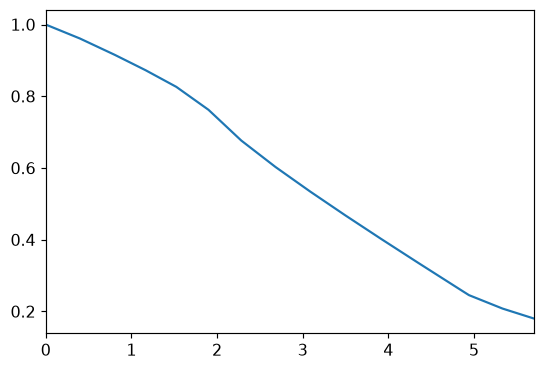

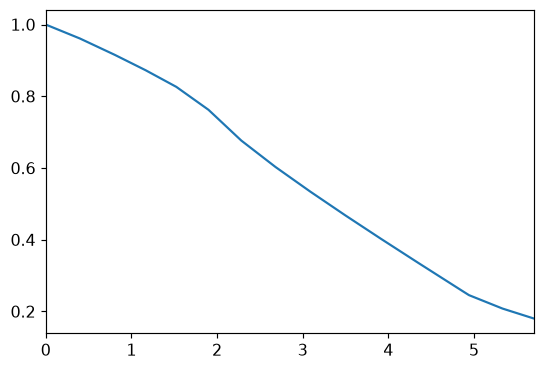

In [77]:
f3zinterp=interpolate.interp1d(zvec,f3zmap,kind="linear",bounds_error=False,fill_value="extrapolate")
lineplot(f3zinterp,(0,.7*zmax))

In [78]:
z1σ=optimize.brentq(lambda t:float(f3zinterp(t))-.683,0,.7*zmax)
z2σ=optimize.brentq(lambda t:float(f3zinterp(t))-.954,0,.7*zmax)
z3σ=optimize.brentq(lambda t:float(f3zinterp(t))-.9973,0,.7*zmax)
display(z1σ);display(z2σ);display(z3σ)

2.2546932355666947

0.46320443410762885

0.027915149747462373

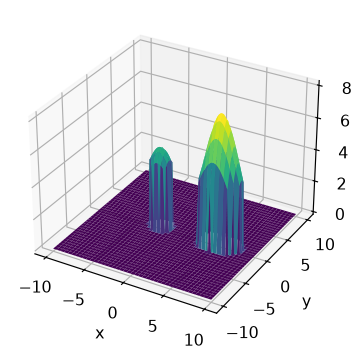

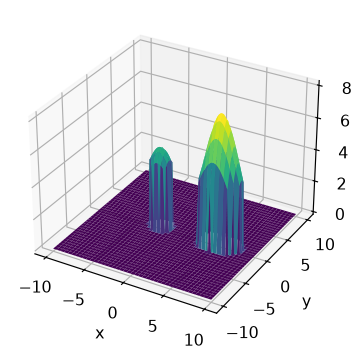

In [79]:
surface(lambda a,b:f2z(a,b,4),(-10,10),(-10,10),n=85)

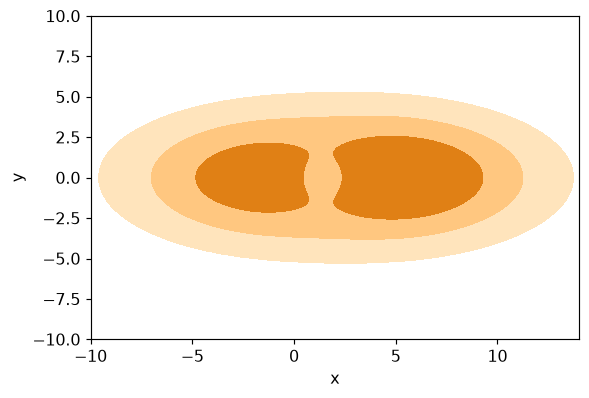

<Axes: xlabel='x', ylabel='y'>

In [80]:
contourplot(posteriortab,[z1σ,z2σ,z3σ],colors=['white','#ffe4bc','#ffc780','#e08015'])

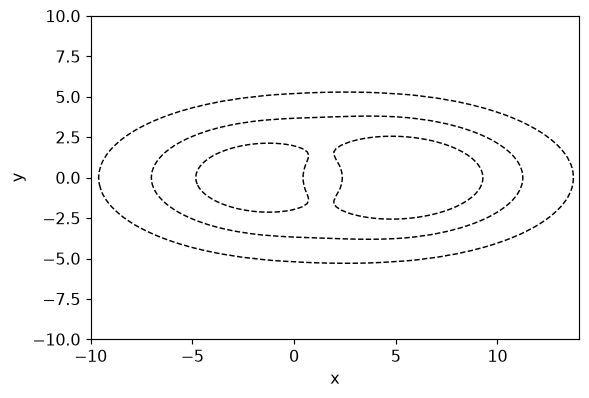

In [81]:
plotsigmas=contourplot(posteriortab,[z1σ,z2σ,z3σ],filled=False,style='dashed')

## Marginalization

### We just analyzed an analytical likelihood as a merely didactic example. It was given by
likelihood2D[x_,y_]:=Exp[-(((x-μx)/(2σx)))^(2)]Exp[-(((y-.03(x)^(2)-μy)/(2σy)))^(4)];
with {μx=2,σx=2,μy=0,σy=1.2}.
 
We will now suppose that there is a third parameter w, and that the likelihood is now described by the function:
likelihood3D[x_,y_,w_]:=Exp[-(((x-μx)/(2σx)))^(2)]Exp[-(((y-.03(x)^(2)+w-μy)/(2σy)))^(4)]((w)^(2)+1)Exp[-(((w-μw)/(2σw)))^(2)];
with the following parameters: {μx=2,σx=2,μy=0,σy=1.2,μw=0,σw=1.5}.
For the particular case w = 0 we recover the class example. Find the 1σ and 2σ contours in the x,y plane marginalizing over the new variable w. Suppose a flat prior (i.e., constant) in all 3 parameters.
Compare the result with the ones obtained in the absence on the variable w.

In [82]:
μx,σx,μy,σy=2,2,0,1.2
display((μx,σx,μy,σy))

(2, 2, 0, 1.2)

In [83]:
def likelihood3D(x,y,w):
    return (np.exp(-((np.asarray(x)-μx)/(2*σx))**2)
            *np.exp(-((np.asarray(y)-.03*np.asarray(x)**2+np.asarray(w)-μy)/(2*σy))**4)
            *(np.asarray(w)**2+1)*np.exp(-((np.asarray(w)-μw)/(2*σw))**2))

In [84]:
μx,σx,μy,σy,μw,σw=2,2,0,1.2,0,1.5
display((μx,σx,μy,σy,μw,σw))

(2, 2, 0, 1.2, 0, 1.5)

In [85]:
# Vectorized evaluation replaces the ten Mathematica subkernels.
print('3D grid evaluation uses vectorized NumPy operations.')

3D grid evaluation uses vectorized NumPy operations.


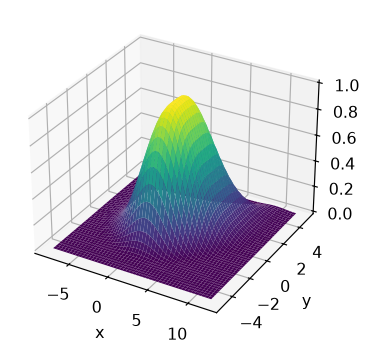

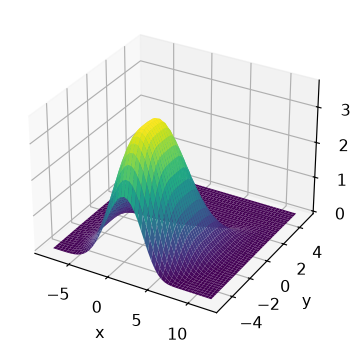

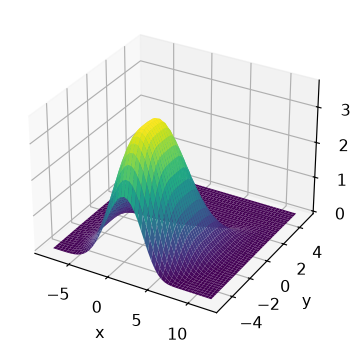

In [86]:
μx,σx,μy,σy,μw,σw=2,2,0,1.2,0,1.5
def likelihood(x,y,w):return likelihood3D(x,y,w)+10**(-9)
surface(lambda a,b:likelihood(a,b,0),(-8,12),(-5,5),n=50)
surface(lambda a,b:likelihood(a,b,3.),(-8,12),(-5,5),n=50)

In [87]:
def prior(x,y,w):return 1.
def posterior(i,j,k):return prior(i,j,k)*likelihood(i,j,k)
xdimension,ydimension,wdimension=50,50,40
xmin,xmax=-10,14;ymin,ymax=-10,10;wmin,wmax=-6,6
xvec=np.linspace(xmin,xmax,xdimension);yvec=np.linspace(ymin,ymax,ydimension)
Δw=(wmax-wmin)/(wdimension-1);wvec=np.linspace(wmin,wmax,wdimension)

In [88]:
t0=perf_counter()
xxx,yyy,www=np.meshgrid(xvec,yvec,wvec,indexing='ij')
posteriortab3D=np.stack([xxx,yyy,www,posterior(xxx,yyy,www)],axis=-1)
display((perf_counter()-t0,None));display(posteriortab3D.shape)

(0.016352348000509664, None)

(50, 50, 40, 4)

In [89]:
posteriortab=posteriortab3D[:,:,0,:][:,:,[0,1,3]].copy()
# Preserve the original endpoint convention: Δw times the full rectangular sum.
posteriortab[:,:,2]=Δw*posteriortab3D[:,:,:,3].sum(axis=2)
posteriorfun=make_interpolator(posteriortab)
local,aux=best_grid_maximum(posteriortab,posteriorfun,[4,2])
display({'local maximum':-local.fun,'parameters':local.x});display(aux)
zmax=aux['maximum'];display(zmax)
posteriorfun=make_interpolator(posteriortab)

{'local maximum': 11.788578728404747,
 'parameters': array([ 2.24489794, -2.65306124])}

{'maximum': 11.792158904796295,
 'x': 2.244897959183673,
 'y': 3.0612244897959187}

11.792158904796295

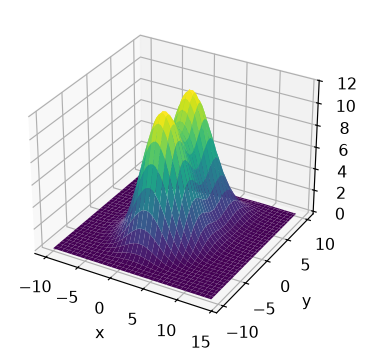

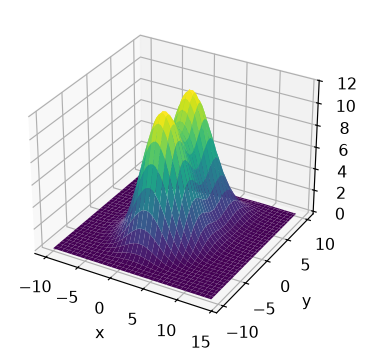

In [90]:
surface(posteriorfun,(xmin,xmax),(ymin,ymax),n=70)

Let's compute the thresholds (contour levels) corresponding to 1, 2 and 3σ

In [91]:
minchisq,chisqrange,postcut,gg,contourstab=log_grid_thresholds(posteriortab,step=.3)
dim1,dim2=posteriortab.shape[:2];display((dim1,dim2))
postInt=posteriortab[:,:,2].sum()
c1sig,c2sig,c3sig=contourstab
display(contourstab);display(gg(contourstab))

(50, 50)

array([-3.25586721,  0.28864439,  5.45926266])

array([0.6827, 0.9545, 0.9973])

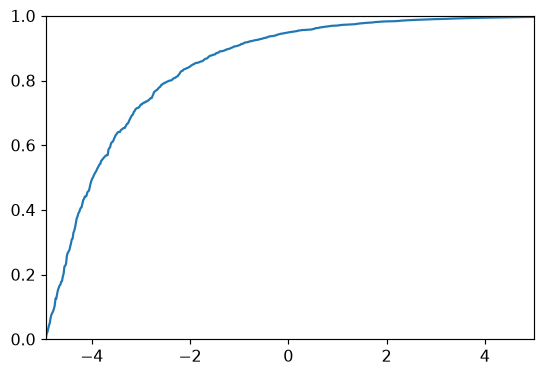

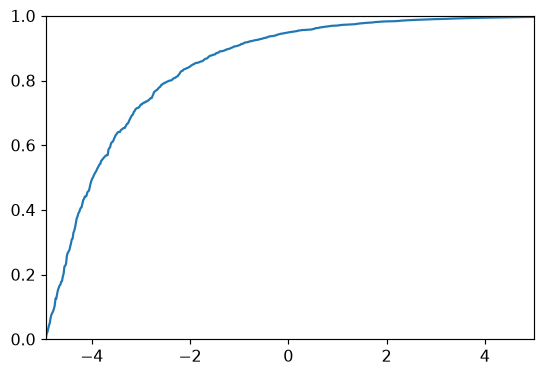

In [92]:
lineplot(postcut,(minchisq,5),ylim=(0,1),n=600)

(2500, 3)

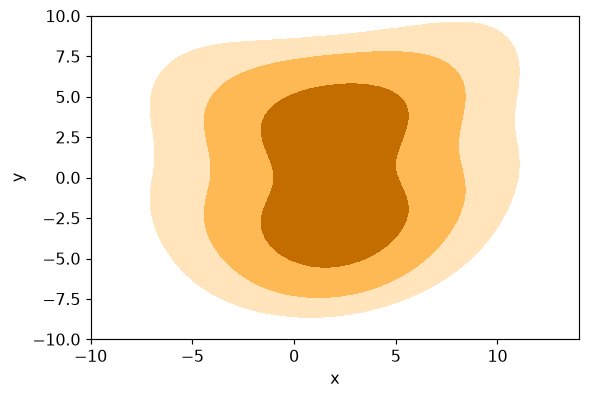

In [93]:
chisqtab=posteriortab.copy();chisqtab[:,:,2]=-2*np.log(posteriortab[:,:,2])
chisqtabflat=chisqtab.reshape(-1,3);display(chisqtabflat.shape)
plot123σ=contourplot(chisqtab,contourstab)

Comparing with the w = 0 case (non-marginalized)

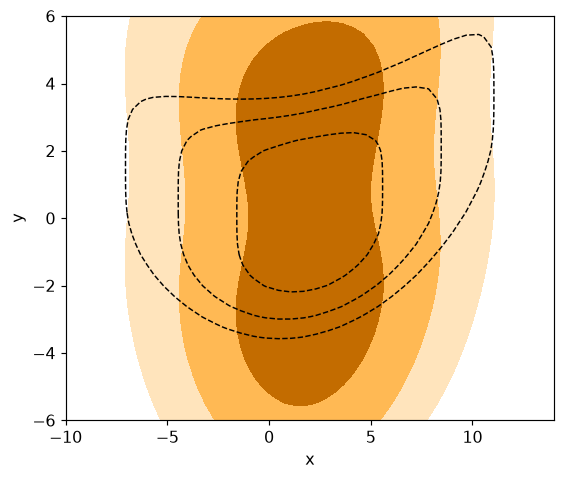

In [94]:
# Recreate the original overlay of marginalized contours and the stored w=0 case.
fig,ax=plt.subplots(figsize=(6,5))
contourplot(chisqtab,contourstab,ax=ax)
contourplot(simple_chisqtab,simple_contours,filled=False,ax=ax,style='dashed')
ax.set_xlim(-10,14);ax.set_ylim(-6,6)
plt.show();plt.close(fig)